# Trabajo experimental ML

## Dataset a usar
https://www.kaggle.com/datasets/straighttoheaven/handwriting-letter-and-number-dataset

## Respuestas I.
1. El reconocimiento óptico de caracteres (OCR, por sus siglas en inglés) es una tecnología que permite identificar caracteres presentes en imágenes o documentos y convertirlos en texto digital editable. En este contexto, el conjunto de datos estudiado contiene imágenes correspondientes a letras mayúsculas y dígitos numéricos, que pueden utilizarse para analizar y desarrollar sistemas de reconocimiento de caracteres.

2. Se verificó el acceso al conjunto de datos y a los archivos que lo componen.

3. Durante la inspección visual se identificaron variaciones en las condiciones de captura y en la apariencia de los caracteres. Entre ellas se encuentran diferencias de iluminación, cambios de perspectiva, desenfoque, variaciones en el grosor de los trazos, sombras, anomalías en los bordes y regiones con relleno vacío, en las que se observan principalmente los contornos del carácter. También se observaron imágenes con elementos ajenos al carácter esperado; por ejemplo, algunas imágenes de la letra U contienen una parte visible de la letra A, o en ocaciones aparecen sombras que dividen la imágen en una mitad iluminada u lo otra con sombra.

4. Se observaron imágenes visualmente similares que presentan diferencias en luminosidad o nivel de desenfoque. Estas observaciones indican la necesidad de comprobar sistemáticamente la existencia de archivos duplicados, identificar imágenes que no puedan leerse correctamente y cuantificar las variaciones presentes en el conjunto de datos.

La inspección visual constituye una evaluación preliminar. La presencia y frecuencia de estas características deberán verificarse mediante procedimientos de análisis que permitan obtener resultados reproducibles.

## Respuestas II.
1. El conjunto de datos está organizado en directorios, cada uno asociado a una clase de caracteres. Para esta actividad se seleccionaron las clases correspondientes a las vocales A, E, I, O y U. Sin embargo, dado que no existe un directorio específico para la letra O, se utilizará el directorio del dígito 0 como aproximación, debido a la similitud visual entre ambos caracteres.

Esta decisión debe tenerse en cuenta al interpretar los resultados, ya que la letra O y el número 0 son caracteres distintos, aunque puedan presentar formas similares.

2. Conteo de archivos por vocal.

- A: 1010
- E: 1010
- I: 1010
- 0 (cero): 1030
- U: 1010


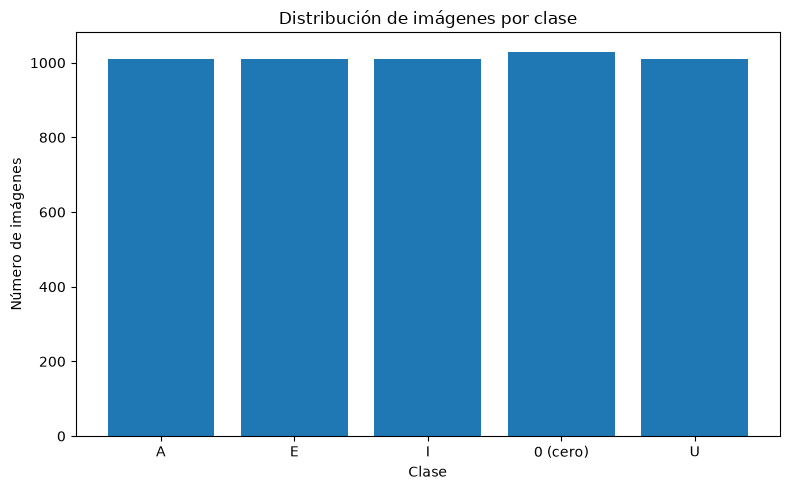

In [3]:
import matplotlib.pyplot as plt

conteos = {
    "A": 1010,
    "E": 1010,
    "I": 1010,
    "0 (cero)": 1030,
    "U": 1010
}

plt.figure(figsize=(8, 5))
plt.bar(conteos.keys(), conteos.values())
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.title("Distribución de imágenes por clase")
plt.tight_layout()
plt.show()


3.  Imágenes
- aug11_0.jpg
- aug3269_8.jpg
- aug2596_15.jpg
- aug17481_0.jpg

| Característica | aug11\_0 (A) | aug3269 \_8 (E)  | aug2596\_15 (I) | aug17481\_0 (0) |
| --------------- | -------- | --------- | ----------- | ----------- |
| Escritura | Normal | Itálica | Itálica | Normal |
| Fondo | Blanco | Sombra completa | Sombra a la mitad | Blanco |
| Iluminación | Baja | Baja | - | Buena |
| Grosor de trazo | Bold | Bold | Bold | Medio |
| Rotación | - | - | - | - |
| Ruido | - | - | - | - |
| Blur | - | - | - | Alto |
    

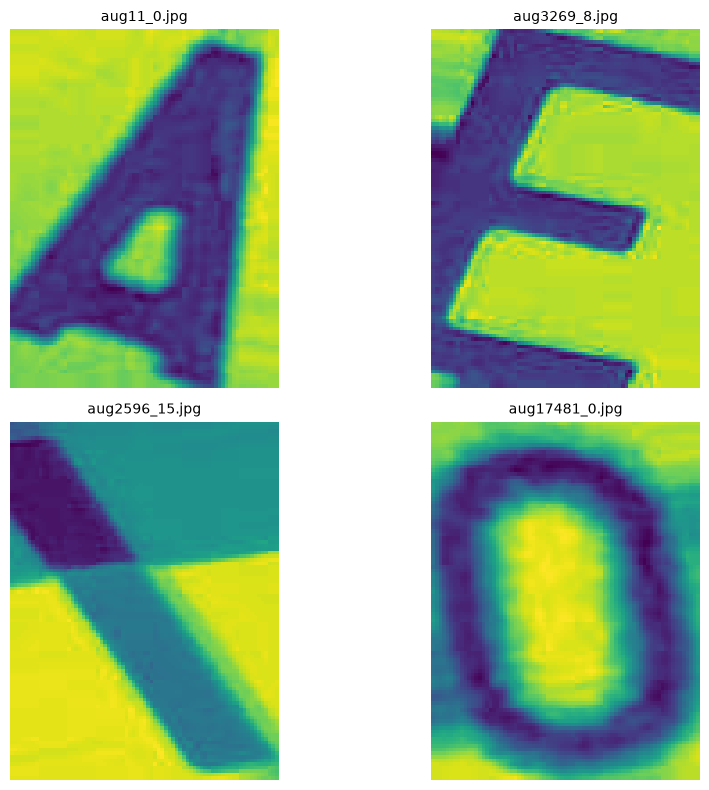

In [6]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Escribe aquí la ruta completa de cada imagen.
imagenes = [
    "aug11_0.jpg",
    "aug3269_8.jpg",
    "aug2596_15.jpg",
    "aug17481_0.jpg",
]

# Distribución de la cuadrícula.
columnas = 2
filas = (len(imagenes) + columnas - 1) // columnas

fig, ejes = plt.subplots(
    filas, columnas,
    figsize=(10, 4 * filas),
    squeeze=False
)

for i, ruta in enumerate(imagenes):
    ax = ejes[i // columnas, i % columnas]
    archivo = Path(ruta)

    try:
        with Image.open(archivo) as img:
            ax.imshow(img.copy())

        ax.set_title(archivo.name, fontsize=10)
    except Exception as error:
        ax.text(
            0.5, 0.5,
            f"No se pudo cargar:\n{archivo.name}\n{error}",
            ha="center", va="center",
            wrap=True
        )

    ax.axis("off")

# Ocultar las celdas que no tengan imágenes.
for i in range(len(imagenes), filas * columnas):
    ejes[i // columnas, i % columnas].axis("off")

plt.tight_layout()
plt.show()